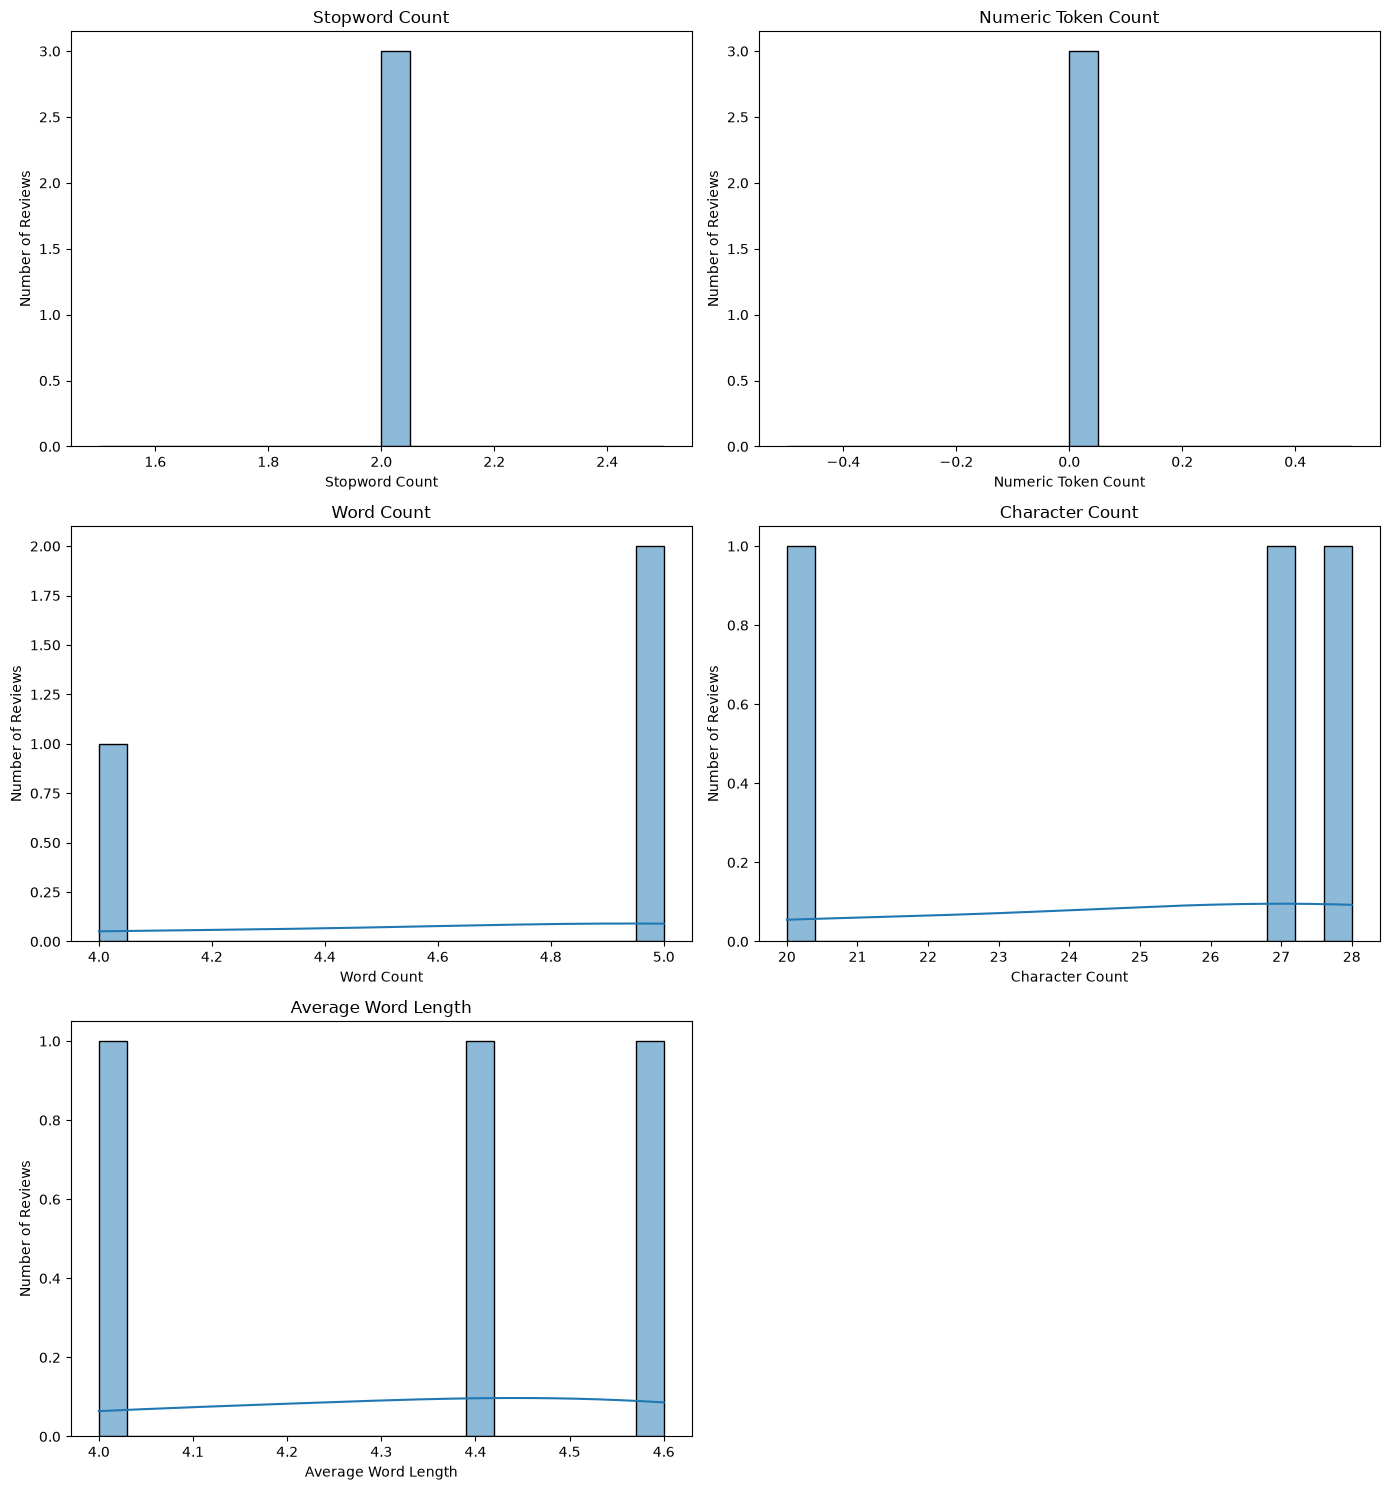

Top 10 stopwords:
[('the', 3), ('very', 1), ('for', 1), ('is', 1)]

Descriptive statistics:
       stopword_count  numeric_count  word_count  character_count  \
count             3.0            3.0    3.000000         3.000000   
mean              2.0            0.0    4.666667        25.000000   
std               0.0            0.0    0.577350         4.358899   
min               2.0            0.0    4.000000        20.000000   
25%               2.0            0.0    4.500000        23.500000   
50%               2.0            0.0    5.000000        27.000000   
75%               2.0            0.0    5.000000        27.500000   
max               2.0            0.0    5.000000        28.000000   

       average_word_length  
count             3.000000  
mean              4.333333  
std               0.305505  
min               4.000000  
25%               4.200000  
50%               4.400000  
75%               4.500000  
max               4.600000  


In [4]:
import re
import pandas as pd
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from nltk.corpus import stopwords
from collections import Counter

nltk.download("stopwords", quiet=True)

df = pd.read_csv("product_reviews.csv")
df["review"] = df["review"].fillna("").astype(str)

stop_words = set(stopwords.words("english"))

def analyze_review(text):
    tokens = re.findall(r"\b[\w']+\b", text.lower())
    words = re.findall(r"\b[A-Za-z]+\b", text)
    numeric_tokens = re.findall(r"\b\d+(?:\.\d+)?\b", text)

    stopword_tokens = [
        token for token in tokens if token in stop_words
    ]

    return pd.Series({
        "word_count": len(tokens),
        "character_count": len(text),
        "numeric_count": len(numeric_tokens),
        "stopword_count": len(stopword_tokens),
        "average_word_length": (
            sum(len(word) for word in words) / len(words)
            if words else 0
        )
    })

statistics = df["review"].apply(analyze_review)
df = pd.concat([df, statistics], axis=1)

# Save calculated statistics
df.to_csv("review_statistics.csv", index=False)

# Plot distributions
columns = [
    ("stopword_count", "Stopword Count"),
    ("numeric_count", "Numeric Token Count"),
    ("word_count", "Word Count"),
    ("character_count", "Character Count"),
    ("average_word_length", "Average Word Length")
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))
axes = axes.flatten()

for i, (column, title) in enumerate(columns):
    sns.histplot(
        data=df, x=column, kde=True,
        ax=axes[i], bins=20
    )
    axes[i].set_title(title)
    axes[i].set_xlabel(title)
    axes[i].set_ylabel("Number of Reviews")
axes[-1].axis("off")
plt.tight_layout()
plt.savefig("review_statistics_distributions.png", dpi=300)
plt.show()
# Most common stopwords
all_tokens = re.findall(
    r"\b[\w']+\b",
    " ".join(df["review"]).lower()
)
stopword_frequency = Counter(
    token for token in all_tokens if token in stop_words
)
print("Top 10 stopwords:")
print(stopword_frequency.most_common(10))

print("\nDescriptive statistics:")
print(df[[
    "stopword_count",
    "numeric_count",
    "word_count",
    "character_count",
    "average_word_length"
]].describe())


In [2]:
%pip install nltk seaborn pandas matplotlib

Defaulting to user installation because normal site-packages is not writeable
  Using cached click-8.5.0-py3-none-any.whl.metadata (2.6 kB)
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ----- ---------------------------------- 0.3/1.8 MB ? eta -:--:--
   ----------- ---------------------------- 0.5/1.8 MB 800.4 kB/s eta 0:00:02
   ----------- ---------------------------- 0.5/1.8 MB 800.4 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 794.2 kB/s eta 0:00:02
   ----------------- ---------------------- 0.8/1.8 MB 794.2 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 743.9 kB/s eta 0:00:02
   ----------------------- ---------------- 1.0/1.8 MB 743.9 kB/s eta 0:00:02
   ----------------------------- ---------- 1.3/1.8 MB 714.4 kB/s eta 0:00:01
   ---------------------------------- 

In [3]:
import nltk

nltk.download("stopwords")

print("NLTK installed successfully!")

[nltk_data] Downloading package stopwords to C:\Users\Golla
[nltk_data]     Sai\AppData\Roaming\nltk_data...


NLTK installed successfully!


[nltk_data]   Unzipping corpora\stopwords.zip.
